In [58]:
using ProjectRoot
using Pkg

Pkg.activate(@projectroot)
using QuantumToolbox
using Revise
using ProgressMeter

include("../src/XoniumUnitCell.jl")
CairoMakie.activate!(type="png")

  Activating project at `~/Projects/xonium/XoniumUnitCell.jl`


In [53]:
"""
    ncell(params::NamedTuple; subsys_nstate=10, diagonalize_subsys=true, set_energy_zero=true, etol=1e-9) -> CompositeQuantumSystem
Construct a composite quantum system representing a unit cell of `fluxonium` qubits, given a `NamedTuple` of parameters for each subsystem.
The function allows for optional diagonalization and truncation of each subsystem.
# Arguments
- `params::NamedTuple`: A `NamedTuple` where each key is a symbol representing a subsystem name, and each value is a `NamedTuple` of
   parameters for the `fluxonium` constructor.
- `subsys_nstate::Int`: The number of states to retain in each subsystem after truncation (default: 10).
- `diagonalize_subsys::Bool`: Whether to diagonalize each subsystem before truncation (default: true).
- `set_energy_zero::Bool`: Whether to set the ground state energy to zero when diagonalizing (default: true).
- `etol::Float64`: The energy tolerance for truncation when diagonalizing (default: 1e-9).
# Returns
- `CompositeQuantumSystem`: A composite quantum system representing the unit cell, with each subsystem constructed according to the 
   provided parameters and optionally diagonalized and truncated.
"""
function ncell(
    params::NamedTuple;
    subsys_nstate=10,
    diagonalize_subsys=true,
    set_energy_zero=true,
    etol=1e-9,)::CompositeQuantumSystem
    return mapreduce(⊗, keys(params), values(params)) do n, p 
        if :EL ∈ keys(p) && p.EL != zero(p.EL)
            sys = fluxonium(;p..., name=n)
        else 
            sys = transmon(;p..., name=n)
        end
        return (diagonalize_subsys ? to_energy_basis(sys; set_energy_zero, etol) : sys) |>
                sys -> truncate(sys, subsys_nstate)
    end
end


"""
    ξ_zz(two_cell::CompositeQuantumSystem; gg::Symbol=:gg, ge::Symbol=:ge, eg::Symbol=:eg, ee::Symbol=:ee)::Float64
Calculate the ZZ coupling strength (ξ_zz) between two subsystems in a composite quantum system representing a two-cell unit of `fluxonium` qubits. The function extracts the relevant energy levels from the subsystems and computes the coupling strength based on the energy differences.
# Arguments
- `two_cell::CompositeQuantumSystem`: A composite quantum system representing a two-cell unit of `fluxonium` qubits, where each subsystem corresponds to a qubit.
- `gg::Symbol`: The symbol representing the ground state energy level (default: :gg).
- `ge::Symbol`: The symbol representing the first excited state energy level (default: :ge).
- `eg::Symbol`: The symbol representing the first excited state energy level of the second subsystem (default: :eg).
- `ee::Symbol`: The symbol representing the second excited state energy level (default: :ee).
# Returns
- `Float64`: The calculated ZZ coupling strength (ξ_zz) between the two subsystems.
"""
function ζ_zz(
    n_cell::CompositeQuantumSystem;
    gg::Symbol=:gg,
    ge::Symbol=:ge,
    eg::Symbol=:eg,
    ee::Symbol=:ee,
)::Float64
    E_ge, E_eg, E_ee = energy.(Ref(n_cell), [ge, eg, ee]) .- energy(n_cell, gg)
    return real(E_ee - (E_ge + E_eg))
end

function to_ħGHz(params::NamedTuple)::NamedTuple 
    return map(keys(params), values(params)) do k, v 
        if k ∈ (:EC, :EL, :EJ)
            return k => 2π * v 
        else 
            return k=>v
        end
    end
end




to_ħGHz (generic function with 1 method)

## FTF Sanity Check

In [ ]:
fl1_params = (EC=1.41, EL=0.80, EJ=6.27) |> to_ħGHz
fl2_params = (EC=1.3, EL=0.59, EJ=5.71) |> to_ħGHz
transmon_params = (EC=0.32, EJ=3.4) |> to_ħGHz
ftf_params = (fl1=fl1_params, cplr=transmon_params, fl2=fl2_params,  )
J_1c, J_2c, J_12 = (570, 560, 125) .* (2π * 1e-3)
ftf = ncell(ftf_params, subsys_nstate=5) |>
    sys -> sys +
     (J_1c*sys[:fl1,:n,:cplr,:n] +
      J_2c * sys[:fl2, :n, :cplr, :n] +
      J_12 * sys[:fl1, :n, :fl2, :n] )


In [65]:
# check energy of each subsystem
ens = (energy(ftf[syslbl], :e) for syslbl in ( :fl1, :cplr, :fl2) ) |> collect
ens/2π

3-element Vector{ComplexF64}:
 0.29805942052632123 + 0.0im
   0.079882933125428 + 0.0im
 0.22198743161599005 + 0.0im

## 2-Cell

In [3]:
flA_params = (;EJ = 7.0, EC=1.0, EL=1.0, δϕ=0.0, n_g=0.0)
flB_params = (;EJ = 7.0, EC=1.0, EL=0.89, δϕ=0.0, n_g=0.0)
two_cell_params = (flA=flA_params, flB=flB_params)
two_cell = ncell(two_cell_params)

CompositeQuantumSystem{@NamedTuple{H::QuantumObject{Operator, Dimensions{TensorSpace{2, Tuple{Space, Space}}, TensorSpace{2, Tuple{Space, Space}}}, Matrix{ComplexF64}}}, @NamedTuple{flA::SimpleQuantumSystem{@NamedTuple{φ::QuantumObject{Operator, Dimensions{Space, Space}, Matrix{ComplexF64}}, n::QuantumObject{Operator, Dimensions{Space, Space}, Matrix{ComplexF64}}, H::QuantumObject{Operator, Dimensions{Space, Space}, Matrix{ComplexF64}}}, @NamedTuple{EC::Float64, EL::Float64, EJ::Float64}}, flB::SimpleQuantumSystem{@NamedTuple{φ::QuantumObject{Operator, Dimensions{Space, Space}, Matrix{ComplexF64}}, n::QuantumObject{Operator, Dimensions{Space, Space}, Matrix{ComplexF64}}, H::QuantumObject{Operator, Dimensions{Space, Space}, Matrix{ComplexF64}}}, @NamedTuple{EC::Float64, EL::Float64, EJ::Float64}}}, @NamedTuple{flA::@NamedTuple{EC::Float64, EL::Float64, EJ::Float64}, flB::@NamedTuple{EC::Float64, EL::Float64, EJ::Float64}}}((flA = SimpleQuantumSystem{@NamedTuple{φ::QuantumObject{Operator

## First Sweep, Check $\zeta_{zz}$ cancellation in nearly degenerate 2-cell

Using the two-cell defined in the previous code block, we would like to sweep over possible inductive and capacitive couplings to see if we can find a region with negligible ZZ coupling.

The inductive coupling strength to be swept will be 4 and 200 MHz.
The capacitive coupling strength to be swept will be between 1 and 100 MHz


In [4]:
# inductive and capacitive coupling strengths in units of GHz [ħ=1]
g_ind_rng = range(1.0, 300.0, length=100) * 2π * 1e-3 |> collect
g_cap_rng = range(1.0, 100.0, length=100) * 2π * 1e-3 |> collect
p = Progress(length(g_ind_rng)*length(g_cap_rng), showspeed=true)
ζ_zz_mtrx = Matrix{Float64}(undef, length(g_ind_rng), length(g_cap_rng))
g_mtrx = Array{Float64,3}(undef, length(g_ind_rng), length(g_cap_rng), 2)
nn, φφ = [two_cell[:flA, oplbl, :flB, oplbl] for oplbl in (:n, :φ)]
for (i, g_ind) in enumerate(g_ind_rng), (j, g_cap) in enumerate(g_cap_rng)
    two_cell_coupled = two_cell + (g_cap*nn + g_ind * φφ)
    ζ_zz_mtrx[i, j] = ζ_zz(two_cell_coupled)
    g_mtrx[i, j, :] = [g_ind, g_cap]
    next!(p)
end
finish!(p)


Progress: 100%|███████████████████████████| Time: 0:02:06 (12.61 ms/it)


[0.004959973234328901 0.0051750210522229344 0.00538456861963915 -0.018336705357045135 -0.01796497781520739 -0.017601146877552362 -0.01724673671942992 -0.04211672670440586 -0.04145472350279321 -0.04081205914692804 -0.040190904514848344 -0.03959331421763779 -0.039021303562859974 -0.03847695124842095 -0.03796252076711089 -0.037480557814430895 -0.037033844803999176 -0.036625011734040196 0.1783114475580936 -0.03515843979008869 -0.0348202690073522 -0.03449379470885422 -0.03418151529366579 -0.03388537285875318 -0.03360663170884014 -0.03334597243546638 -0.033103635973376316 -0.03287955050828726 -0.03267342682553541 -0.03248482583303204 -0.032313205484501256 -0.03215795337437261 -0.03201840955289096 -0.031893882671447014 -0.031783661540341124 -0.031687023492768994 -0.031603240500464154 -0.031531583690286955 -0.031471326715884235 -0.03142174830292558 -0.03138213420418299 -0.03135177872326906 -0.031329985932292644 -0.03131607066255202 -0.031309359327946505 -0.031309190615630776 -0.031314916062119

┌ Warning: Found `resolution` in the theme when creating a `Scene`. The `resolution` keyword for `Scene`s and `Figure`s has been deprecated. Use `Figure(; size = ...` or `Scene(; size = ...)` instead, which better reflects that this is a unitless size and not a pixel resolution. The key could also come from `set_theme!` calls or related theming functions.
└ @ Makie /home/dom/.julia/packages/Makie/p9K7f/src/scenes.jl:264


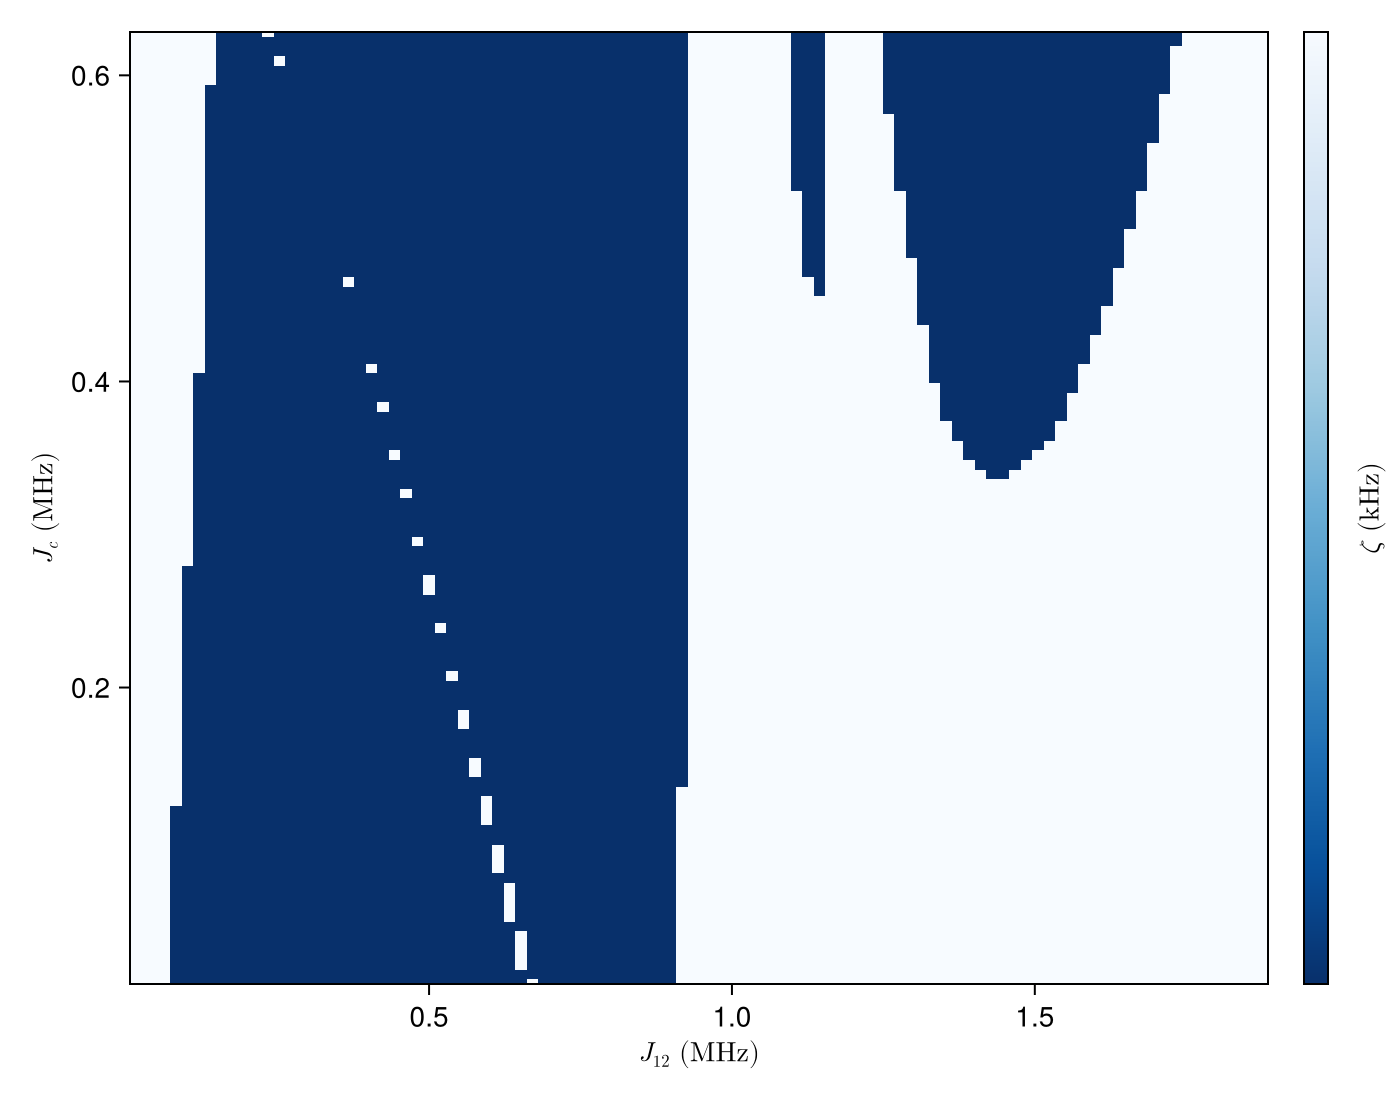

In [29]:
Z = clamp.(abs.(ζ_zz_mtrx), 1e-12, 1e-10)
print(ζ_zz_mtrx)
fig, ax = zz_heatmap_figure(Z, x=g_ind_rng, y=g_cap_rng)
fig